<img src=https://audiovisuales.icesi.edu.co/assets/custom/images/ICESI_logo_prin_descriptor_RGB_POSITIVO_0924.jpg width=200>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juanestebancg2806/ml3-time-series-forecasting/blob/main/taller2/taller2_pronostico_ocupados.ipynb)

# Pronóstico del número de ocupados en las 13 principales ciudades de Colombia: suavización exponencial, ARIMA y Prophet con optimización bayesiana

**Aprendizaje Automático III — Universidad Icesi**

**Integrantes:** Juan Esteban Cardona, Daniel Velasco

Este notebook continúa el pronóstico del número mensual de ocupados, en miles de personas, de las 13 principales ciudades de Colombia, con el objetivo de pronosticar los próximos 6 meses. En el taller anterior se compararon promedios móviles, suavización exponencial y regresión lineal, y el mejor modelo fue la combinación de un Holt-Winters aditivo sin tendencia y una regresión con tendencia lineal y dummies de mes estimada con los últimos 24 meses. Aquí se agregan tres familias de modelos sobre el mismo problema: suavización exponencial con parámetros ajustados por optimización bayesiana, modelos ARIMA con y sin componente estacional, y Prophet.

Los hiperparámetros de cada familia se ajustan con optimización bayesiana mediante la librería Optuna. En lugar de evaluar todas las combinaciones posibles, como en una búsqueda en grilla, Optuna usa los resultados de los intentos anteriores para decidir qué combinación probar a continuación, lo que permite explorar espacios con hiperparámetros continuos o con muchas combinaciones que una grilla no podría cubrir.

Todos los modelos se evalúan con el mismo esquema del taller anterior: una validación con origen móvil dentro del entrenamiento, con los mismos 6 cortes y las mismas métricas, y una muestra de prueba con los 6 meses más recientes, que no se usa para tomar ninguna decisión de modelado. Así, los modelos nuevos se comparan directamente con los del taller anterior.

### Contenido

**Preparación común**

1. **Carga de paquetes:** librerías y versiones del entorno.
2. **Carga, exploración y partición de los datos:** periodo, comportamiento general, muestra de prueba y rasgos de la serie de entrenamiento que orientan los modelos.
3. **Esquema de validación y funciones comunes:** cortes de validación, métricas y funciones de evaluación y de optimización compartidas por todas las familias.
4. **Punto de partida: resultados del taller anterior:** modelos de referencia y mejor modelo del taller anterior, recalculados con el mismo protocolo.

**Parte I — Suavización exponencial**

5. **Suavización exponencial con optimización bayesiana:** estructura, ventana de estimación y parámetros de suavización elegidos para el horizonte de 6 meses.

**Parte II — Modelos ARIMA**

6. **Identificación:** estacionariedad, orden de diferenciación y autocorrelaciones de la serie.
7. **ARIMA y SARIMA con optimización bayesiana:** espacio de búsqueda, optimización y comparación con la selección por criterios de información.

**Parte III — Prophet**

8. **Prophet con optimización bayesiana:** tendencia por tramos, estacionalidad anual y puntos de cambio.

**Parte IV — Comparación final, prueba y pronóstico**

9. **Comparación de los modelos:** mejor modelo de cada familia, combinaciones y comparación con el mejor modelo del taller anterior.
10. **Evaluación de los supuestos de los errores:** revisión de los candidatos y elección del modelo final.
11. **Evaluación en la muestra de prueba:** desempeño de los modelos finalistas en enero a junio de 2019.
12. **Pronóstico de los próximos 6 meses:** pronóstico de julio a diciembre de 2019 con sus intervalos de predicción.
13. **Informe de resultados y limitaciones.**

## 1. Carga de paquetes

El notebook se desarrolló con Python 3.13 y las versiones de las librerías que se instalan en la celda siguiente. En un entorno que ya las tenga no hace falta instalarlas; en Google Colab, la celda de instalación se descomenta y se reinicia la sesión antes de continuar.

Además de las librerías del taller anterior, se usan Optuna para la optimización bayesiana, Prophet para los modelos con tendencia por tramos y pmdarima para la selección automática de modelos ARIMA por criterios de información. Después de cargar los paquetes se imprimen las versiones del entorno. Los modelos de suavización exponencial, ARIMA y Prophet se estiman con optimizadores numéricos, por lo que sus resultados pueden variar levemente entre sistemas operativos o procesadores, aun con las mismas versiones. La optimización bayesiana, en cambio, usa una semilla fija, de modo que la secuencia de intentos se repite en cada ejecución.

In [1]:
# Instalación de las librerías con las versiones usadas en este notebook.
# Solo es necesaria en Google Colab o en un entorno que no las tenga instaladas:
# quitar el comentario de la línea %pip y, en Colab, reiniciar la sesión después
# de instalar (Entorno de ejecución > Reiniciar sesión) para que se carguen las
# versiones nuevas. Requiere Python 3.12 o superior.

# %pip install pandas==3.1.1 numpy==2.5.4 matplotlib==3.11.2 statsmodels==0.15.0 scikit-learn==1.9.1 scipy==1.18.1 openpyxl==3.1.5 optuna==5.1.0 prophet==1.5.0 pmdarima==2.1.1

In [2]:
import logging

# Optuna y Prophet (a través de cmdstanpy) imprimen un mensaje por cada intento o ajuste, y Prophet
# avisa al importarse que no encuentra plotly, que no se usa porque las gráficas se hacen con matplotlib.
# Se dejan solo las advertencias y los errores relevantes. Debe configurarse antes de importar Prophet.
logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
logging.getLogger("prophet").setLevel(logging.WARNING)
logging.getLogger("prophet.plot").setLevel(logging.CRITICAL)

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

# Validación y métricas
from sklearn.model_selection import TimeSeriesSplit                # validación con origen móvil
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

# Descripción de la serie e identificación de modelos ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose            # descomposición (solo para describir la serie)
from statsmodels.tsa.stattools import adfuller, kpss               # pruebas de raíz unitaria y de estacionariedad
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf      # ACF y PACF

# Modelos
from statsmodels.tsa.exponential_smoothing.ets import ETSModel     # suavización exponencial (SES, Holt, Holt-Winters)
from statsmodels.tsa.statespace.sarimax import SARIMAX             # ARIMA y SARIMA
import statsmodels.api as sm                                       # regresión lineal por MCO y gráfico Q-Q
from pmdarima import auto_arima                                    # selección de ARIMA por criterios de información
from prophet import Prophet                                        # tendencia por tramos y estacionalidad de Fourier

# Optimización bayesiana de hiperparámetros
import optuna
from optuna.visualization import matplotlib as optuna_graficas    # gráficas de los estudios con matplotlib

# Supuestos de los errores
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch  # autocorrelación y efectos ARCH
from statsmodels.sandbox.stats.runs import runstest_1samp          # prueba de rachas
from scipy import stats                                            # Jarque-Bera, Shapiro-Wilk, normal y t de Student

# Optuna solo muestra advertencias y errores, no un mensaje por cada intento
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [3]:
# Versiones del entorno de ejecución, para poder reproducir los resultados
import platform
import sys

import matplotlib
import openpyxl
import pmdarima
import prophet
import scipy
import sklearn
import statsmodels

print(f"{'Python':<14}{sys.version.split()[0]}")
print(f"{'Plataforma':<14}{platform.platform()}")
for nombre_libreria, modulo in [
    ("pandas", pd),
    ("numpy", np),
    ("matplotlib", matplotlib),
    ("statsmodels", statsmodels),
    ("scikit-learn", sklearn),
    ("scipy", scipy),
    ("openpyxl", openpyxl),
    ("optuna", optuna),
    ("prophet", prophet),
    ("pmdarima", pmdarima),
]:
    print(f"{nombre_libreria:<14}{modulo.__version__}")

Python        3.13.9
Plataforma    macOS-27.0.1-arm64-arm-64bit-Mach-O
pandas        3.1.1
numpy         2.5.4
matplotlib    3.11.2
statsmodels   0.15.0
scikit-learn  1.9.1
scipy         1.18.1
openpyxl      3.1.5
optuna        5.1.0
prophet       1.5.0
pmdarima      2.1.1


## 2. Carga, exploración y partición de los datos

Los datos provienen del archivo `datosEmpleo.xlsx`, que contiene series mensuales del mercado laboral de las 13 principales ciudades de Colombia. Se usa la columna `Ocupados`, que corresponde al número de ocupados en miles de personas, la misma serie del taller anterior. Primero se revisa el periodo cubierto, si hay valores faltantes y el comportamiento general de la serie. Después se separa la muestra de prueba y, solo con el entrenamiento, se miden los rasgos que orientan la configuración de las tres familias de modelos: el cambio de la tendencia en los últimos años y la forma y el tamaño del patrón estacional.

Observaciones: 222
Periodo: 2001-01 a 2019-06
Valores faltantes: 0
count      222.0
mean      9160.9
std       1295.5
min       6923.6
25%       7971.1
50%       9139.1
75%      10458.5
max      11037.2
Name: Ocupados, dtype: float64


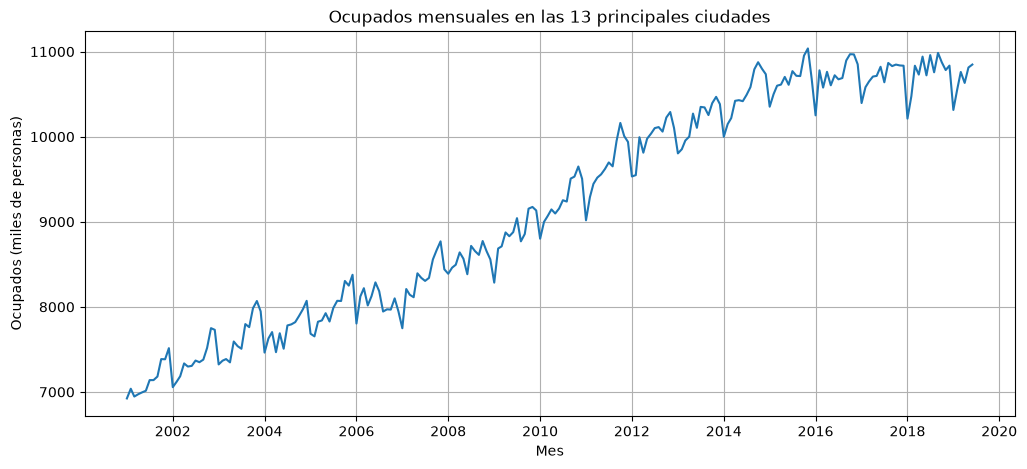

In [4]:
# Carga de datos: la columna "mes" se usa como índice de fechas
data = pd.read_excel(
    "https://raw.githubusercontent.com/dagudelo30/Aprendizaje-automatico-III/main/Clase_1/datosEmpleo.xlsx",
    index_col="mes",
    parse_dates=True,
)

# Serie de ocupados (miles de personas).
# asfreq("MS") declara la frecuencia mensual (inicio de mes): si faltara algún mes,
# aparecería como valor faltante, y además evita la advertencia de frecuencia de statsmodels.
ocupados = data["Ocupados"].asfreq("MS")

print("Observaciones:", len(ocupados))
print("Periodo:", ocupados.index.min().strftime("%Y-%m"), "a", ocupados.index.max().strftime("%Y-%m"))
print("Valores faltantes:", ocupados.isna().sum())
print(ocupados.describe().round(1))

# Gráfica de la serie completa
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ocupados)
ax.set_title("Ocupados mensuales en las 13 principales ciudades")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.grid()
plt.show()

### Lectura de la serie

La serie tiene 222 observaciones mensuales, de enero de 2001 a junio de 2019, sin valores faltantes. El número de ocupados va de un mínimo de 6,924 mil personas a un máximo de 11,037 mil, con una media de 9,161 mil. La serie crece de forma casi continua hasta 2015 y desde entonces se mantiene en un nivel casi constante, con un patrón que se repite todos los años: una caída fuerte en enero y los valores más altos hacia el final del año.

Como el objetivo es pronosticar los próximos 6 meses, los últimos 6 meses de la serie, de enero a junio de 2019, se reservan como muestra de prueba, igual que en el taller anterior. La partición respeta el orden temporal, y la muestra de prueba solo se usa al final, para evaluar los modelos finalistas ya elegidos.

In [5]:
# Horizonte de pronóstico: 6 meses
horizonte = 6

# Partición temporal: los últimos 6 meses se reservan como prueba y no se usan
# para ninguna decisión de modelado hasta la sección 11
train = ocupados.iloc[:-horizonte]
test = ocupados.iloc[-horizonte:]

print("Entrenamiento:", train.index.min().strftime("%Y-%m"), "a", train.index.max().strftime("%Y-%m"), f"({len(train)} meses)")
print("Prueba:       ", test.index.min().strftime("%Y-%m"), "a", test.index.max().strftime("%Y-%m"), f"({len(test)} meses)")

Entrenamiento: 2001-01 a 2018-12 (216 meses)
Prueba:        2019-01 a 2019-06 (6 meses)


Pendiente de la tendencia (miles de personas por año):
2001-2015    261.7
2016-2018     15.2

Efecto estacional de cada mes frente a la tendencia:
     Aditivo (miles)  Multiplicativo (%)
Ene           -310.5                -3.4
Feb           -134.2                -1.4
Mar            -59.5                -0.7
Abr            -57.3                -0.7
May              6.5                 0.1
Jun            -35.8                -0.4
Jul             27.7                 0.3
Ago             14.3                 0.1
Sep             63.8                 0.6
Oct            186.0                 2.0
Nov            200.8                 2.2
Dic             98.1                 1.2

Caída de enero frente a la tendencia, por año:
      Tendencia (miles)  Caída (miles)  Caída (%)
mes                                              
2002             7263.4          207.0        2.9
2003             7476.8          153.3        2.1
2004             7722.0          259.6        3.4
2005             7849.

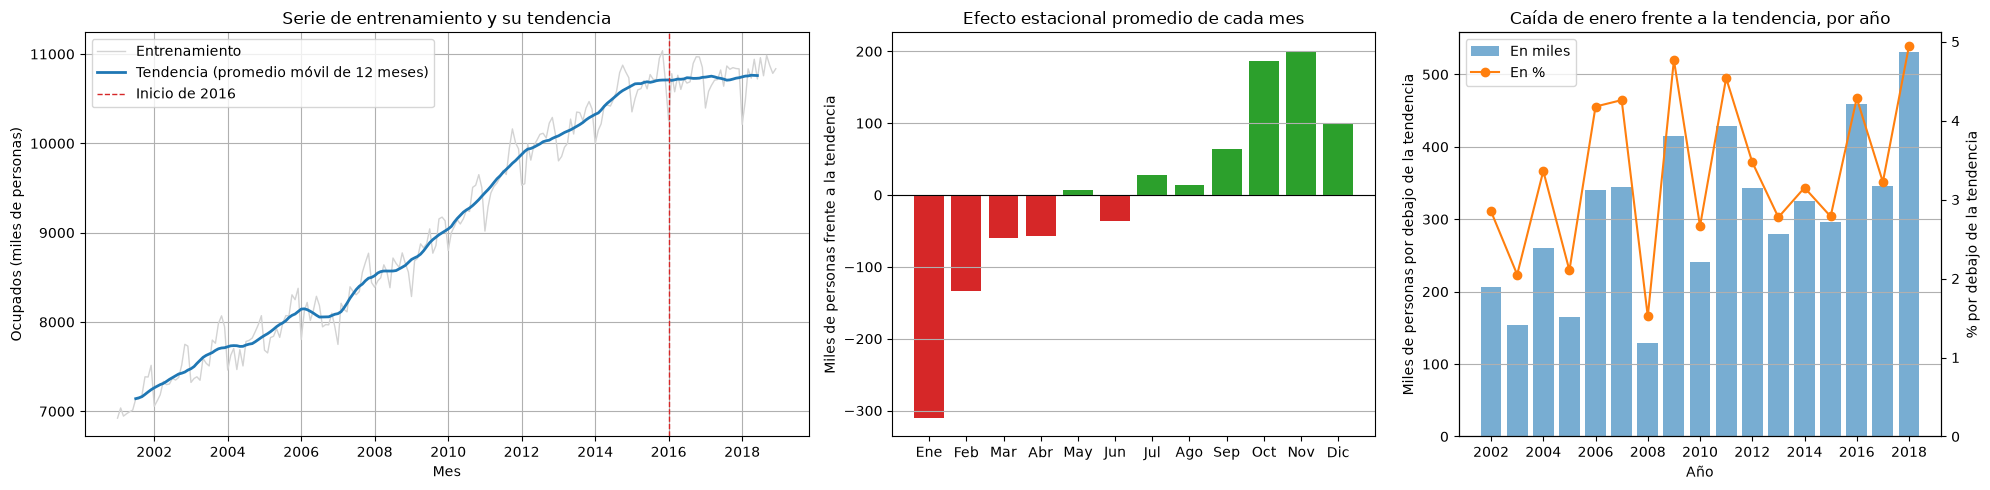

In [6]:
# Rasgos de la serie de entrenamiento que orientan la configuración de los modelos.
# Solo se usa el entrenamiento, para que ninguna decisión dependa de la muestra de prueba.
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
anio_cambio = "2016"   # año desde el que la serie deja de crecer, según la gráfica anterior


def pendiente_anual(serie):
    """Pendiente de una tendencia lineal con dummies de mes, en miles de personas por año.

    Las dummies evitan que el patrón estacional se confunda con la tendencia
    cuando el periodo no empieza y termina en el mismo mes.
    """
    t = np.arange(len(serie)) / 12
    dummies_mes = pd.get_dummies(serie.index.month, drop_first=True, dtype=float).to_numpy()
    X = sm.add_constant(np.column_stack([t, dummies_mes]))
    return sm.OLS(serie.to_numpy(), X).fit().params[1]


# 1. Cambio de la tendencia: pendiente antes y después del año de cambio
periodos = {"2001-2015": train.loc[:"2015"], f"{anio_cambio}-2018": train.loc[anio_cambio:]}
pendientes = pd.Series({nombre: pendiente_anual(serie) for nombre, serie in periodos.items()})
print("Pendiente de la tendencia (miles de personas por año):")
print(pendientes.round(1).to_string())

# 2. Patrón estacional: efecto de cada mes con la descomposición clásica aditiva y multiplicativa
desc_aditiva = seasonal_decompose(train, model="additive")
desc_multiplicativa = seasonal_decompose(train, model="multiplicative")
efectos_estacionales = pd.DataFrame({
    "Aditivo (miles)": desc_aditiva.seasonal.iloc[:12].to_numpy(),          # el entrenamiento empieza en enero
    "Multiplicativo (%)": 100 * (desc_multiplicativa.seasonal.iloc[:12].to_numpy() - 1),
}, index=nombres_meses)
print("\nEfecto estacional de cada mes frente a la tendencia:")
print(efectos_estacionales.round(1).to_string())

# 3. Tamaño de la caída de enero frente a la tendencia en cada año.
# Si la caída fuera estable en miles, el efecto sería aditivo; si fuera estable en porcentaje,
# multiplicativo; si crece incluso en porcentaje, el patrón estacional cambió con el tiempo.
es_enero = train.index.month == 1
tendencia_enero = desc_aditiva.trend[es_enero].dropna()   # enero de 2001 no tiene tendencia
caida_enero = pd.DataFrame({
    "Tendencia (miles)": tendencia_enero,
    "Caída (miles)": tendencia_enero - train[tendencia_enero.index],
})
caida_enero["Caída (%)"] = 100 * caida_enero["Caída (miles)"] / caida_enero["Tendencia (miles)"]
caida_enero.index = caida_enero.index.year
print("\nCaída de enero frente a la tendencia, por año:")
print(caida_enero.round(1).to_string())

tabla_enero = pd.DataFrame({
    "2002-2005": caida_enero.loc[2002:2005].mean(),
    "2016-2018": caida_enero.loc[2016:2018].mean(),
}).T
tabla_enero.loc["Cociente 2016-2018 / 2002-2005"] = tabla_enero.loc["2016-2018"] / tabla_enero.loc["2002-2005"]
print("\nPromedio de enero al inicio y al final del entrenamiento:")
print(tabla_enero.round(2).to_string())

# Gráficas: tendencia con el año de cambio, efecto de cada mes y caída de enero por año
fig, axes = plt.subplots(1, 3, figsize=(20, 5), gridspec_kw={"width_ratios": [3, 2, 2]})

axes[0].plot(train, color="lightgray", linewidth=1, label="Entrenamiento")
axes[0].plot(desc_aditiva.trend, color="C0", linewidth=2, label="Tendencia (promedio móvil de 12 meses)")
axes[0].axvline(pd.Timestamp(f"{anio_cambio}-01-01"), color="C3", linestyle="--", linewidth=1,
                label=f"Inicio de {anio_cambio}")
axes[0].set_title("Serie de entrenamiento y su tendencia")
axes[0].set_xlabel("Mes")
axes[0].set_ylabel("Ocupados (miles de personas)")
axes[0].legend(loc="upper left")
axes[0].grid()

colores_barras = ["C3" if efecto < 0 else "C2" for efecto in efectos_estacionales["Aditivo (miles)"]]
axes[1].bar(nombres_meses, efectos_estacionales["Aditivo (miles)"], color=colores_barras)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Efecto estacional promedio de cada mes")
axes[1].set_ylabel("Miles de personas frente a la tendencia")
axes[1].grid(axis="y")

# Caída de enero en miles (barras, eje izquierdo) y en porcentaje (línea, eje derecho)
axes[2].bar(caida_enero.index, caida_enero["Caída (miles)"], color="C0", alpha=0.6, label="En miles")
axes[2].set_ylabel("Miles de personas por debajo de la tendencia")
axes[2].set_xlabel("Año")
axes[2].set_xticks(caida_enero.index[::2])   # años enteros, uno de cada dos para que se lean
eje_porcentaje = axes[2].twinx()
eje_porcentaje.plot(caida_enero.index, caida_enero["Caída (%)"], color="C1", marker="o", label="En %")
eje_porcentaje.set_ylabel("% por debajo de la tendencia")
eje_porcentaje.set_ylim(bottom=0)
axes[2].set_title("Caída de enero frente a la tendencia, por año")
lineas = axes[2].get_legend_handles_labels()[0] + eje_porcentaje.get_legend_handles_labels()[0]
etiquetas = axes[2].get_legend_handles_labels()[1] + eje_porcentaje.get_legend_handles_labels()[1]
axes[2].legend(lineas, etiquetas, loc="upper left")
axes[2].grid(axis="y")

fig.tight_layout()
plt.show()

### Rasgos de la serie de entrenamiento

**Cambio de la tendencia.** Con una tendencia lineal y dummies de mes, la serie creció 261.7 mil personas por año entre 2001 y 2015, y solo 15.2 mil por año entre 2016 y 2018, cerca de 94 % menos. En la gráfica de la izquierda, la tendencia sube de forma casi continua hasta 2015 y luego se aplana alrededor de 10,700 mil. Este cambio afecta a cualquier modelo que estime una pendiente con toda la historia, porque tendería a extender hacia el futuro un crecimiento que ya no ocurre. Por eso, en cada familia se incluyen alternativas que pueden adaptarse a él: tendencias amortiguadas o ausentes y ventanas de estimación cortas en la suavización exponencial, diferenciación en los modelos ARIMA, que pronostican a partir del nivel reciente, y puntos de cambio de la tendencia en Prophet.

**Forma del patrón estacional.** Enero es el mes con el mayor efecto: queda 310.5 mil personas (3.4 %) por debajo de la tendencia, y febrero 134.2 mil. Desde septiembre la serie sube, hasta alcanzar sus valores más altos en octubre y noviembre, con 186.0 y 200.8 mil por encima de la tendencia. Entre diciembre y enero el efecto pasa de +98.1 a -310.5 mil, un cambio de 408.6 mil personas en un solo mes. Un patrón tan brusco requiere que cada mes pueda tener su propio efecto, o una representación con suficientes términos de alta frecuencia.

**Tamaño del patrón estacional.** Entre 2002-2005 y 2016-2018, la tendencia de enero aumentó 42 % (de 7,577.8 a 10,731.9 mil). Si el efecto estacional fuera aditivo, la caída de enero sería parecida en miles de personas en ambos periodos; si fuera multiplicativo, habría crecido en la misma proporción que el nivel, es decir, 1.42 veces. En realidad se multiplicó por 2.27 (de 196.3 a 445.5 mil personas) y pasó de 2.59 % a 4.15 % del nivel. El supuesto multiplicativo describe mejor la serie que el aditivo, porque la caída sí creció con el nivel, pero tampoco basta: creció incluso como porcentaje. Además, varía bastante de un año a otro, entre 129.6 mil (1.5 %) en 2008 y 531.6 mil (4.9 %) en 2018. Esto es un indicio, no una prueba, porque la descomposición clásica supone un mismo patrón para todos los años y estima la tendencia con un promedio móvil, pero sugiere que el patrón estacional cambió con el tiempo.

Estos rasgos orientan dos decisiones comunes a las tres familias. Primero, se evalúan versiones aditivas y multiplicativas de la estacionalidad, como pide el enunciado: la multiplicativa describe mejor la historia completa, pero en los años recientes, en los que el nivel cambió poco, las dos pueden pronosticar de forma parecida. Segundo, los modelos deben poder darle más peso al patrón estacional reciente: en la suavización exponencial, con el parámetro de actualización de la estacionalidad $\gamma$; en los modelos ARIMA, con la componente estacional, que relaciona cada mes con el mismo mes de años anteriores; y en las tres familias, con ventanas de estimación que usan solo los años más recientes. La elección final entre estas alternativas se hace con el error de pronóstico en la validación.

## 3. Esquema de validación y funciones comunes

Para elegir entre modelos y configuraciones sin usar la muestra de prueba, se aplica la misma validación con origen móvil del taller anterior. Se definen 6 cortes en el tiempo dentro del entrenamiento, y en cada uno el modelo se ajusta con los meses anteriores al corte y pronostica los 6 meses siguientes. Ajustar significa volver a estimar los parámetros del modelo solo con los datos disponibles hasta el corte, de modo que ningún pronóstico usa información posterior. Los 6 cortes cubren los semestres de 2016 a 2018, y en cada uno se calculan dos métricas:

- **RMSE** (raíz del error cuadrático medio), en miles de personas, que penaliza más los errores grandes.
- **MAPE** (error porcentual absoluto medio), en porcentaje del valor real, que permite leer el error en términos relativos.

El criterio principal de selección es el RMSE promedio de los 6 cortes, y el MAPE promedio se usa como complemento. Entre los mejores modelos se revisa además en cuántos cortes cada uno supera al naive estacional, para que la elección no dependa de un solo semestre.

En este esquema hay que distinguir dos ventanas. La primera es la del protocolo de evaluación: en cada corte, los datos disponibles van desde enero de 2001 hasta el mes anterior al corte, de modo que la historia disponible crece de un corte al siguiente (ventana recursiva). La segunda es la ventana de estimación de cada modelo: dentro de los datos disponibles en un corte, el modelo puede usar toda la historia (ventana recursiva) o solo los últimos $w$ meses (ventana móvil). La primera es igual para todos los modelos, y la segunda es un hiperparámetro que se busca en cada familia.

Corte 1: ajuste 2001-01 a 2015-12 (180 meses) | validación 2016-01 a 2016-06
Corte 2: ajuste 2001-01 a 2016-06 (186 meses) | validación 2016-07 a 2016-12
Corte 3: ajuste 2001-01 a 2016-12 (192 meses) | validación 2017-01 a 2017-06
Corte 4: ajuste 2001-01 a 2017-06 (198 meses) | validación 2017-07 a 2017-12
Corte 5: ajuste 2001-01 a 2017-12 (204 meses) | validación 2018-01 a 2018-06
Corte 6: ajuste 2001-01 a 2018-06 (210 meses) | validación 2018-07 a 2018-12


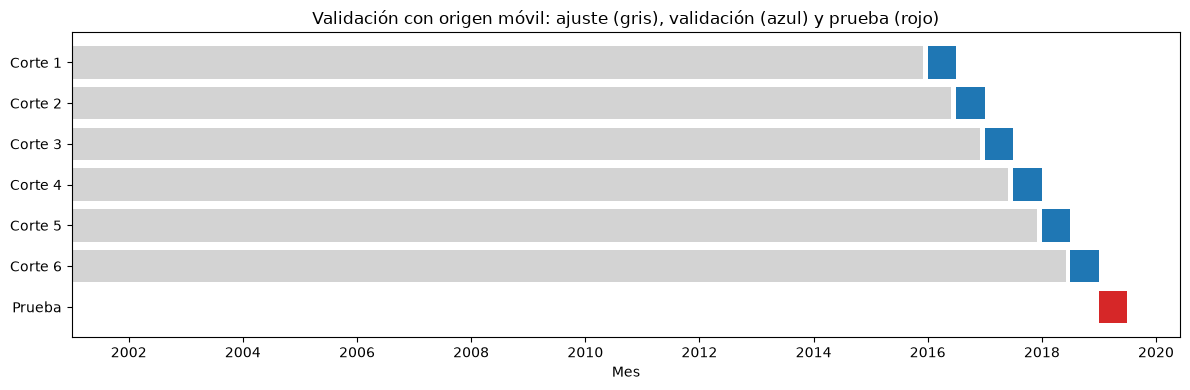

In [7]:
# Validación con origen móvil dentro del entrenamiento (la muestra de prueba no se usa aquí).
# TimeSeriesSplit no mezcla los datos: cada corte ajusta con los meses anteriores
# y valida con los 6 meses siguientes. Por defecto la ventana de ajuste es expansiva
# (max_train_size=None), es decir, cada corte tiene disponible toda la historia hasta ese punto.
n_cortes = 6
tscv = TimeSeriesSplit(n_splits=n_cortes, test_size=horizonte)

for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    print(
        f"Corte {numero}: ajuste {train.index[idx_ajuste[0]]:%Y-%m} a {train.index[idx_ajuste[-1]]:%Y-%m} "
        f"({len(idx_ajuste)} meses) | validación {train.index[idx_validacion[0]]:%Y-%m} "
        f"a {train.index[idx_validacion[-1]]:%Y-%m}"
    )

# Diagrama de los cortes de validación y de la muestra de prueba
fig, ax = plt.subplots(figsize=(12, 4))
for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    inicio_ajuste, fin_ajuste = train.index[idx_ajuste[0]], train.index[idx_ajuste[-1]]
    inicio_validacion, fin_validacion = train.index[idx_validacion[0]], train.index[idx_validacion[-1]]
    # Barra gris: meses disponibles para ajustar; barra azul: meses de validación
    ax.barh(numero, fin_ajuste - inicio_ajuste, left=inicio_ajuste, color="lightgray")
    ax.barh(numero, fin_validacion - inicio_validacion + pd.Timedelta(days=30),
            left=inicio_validacion, color="C0")

# Muestra de prueba, reservada hasta el final
ax.barh(n_cortes + 1, test.index[-1] - test.index[0] + pd.Timedelta(days=30),
        left=test.index[0], color="C3")

ax.set_yticks(range(1, n_cortes + 2))
ax.set_yticklabels([f"Corte {numero}" for numero in range(1, n_cortes + 1)] + ["Prueba"])
ax.invert_yaxis()
ax.set_title("Validación con origen móvil: ajuste (gris), validación (azul) y prueba (rojo)")
ax.set_xlabel("Mes")
plt.tight_layout()
plt.show()

Los 6 cortes validan semestres consecutivos entre enero de 2016 y diciembre de 2018. En cada uno, los datos disponibles para ajustar el modelo van desde enero de 2001 hasta el mes anterior al corte (gris), entre 180 y 210 meses, y el modelo se evalúa en los 6 meses siguientes (azul). La muestra de prueba (rojo) queda por fuera de todos los cortes. Son exactamente los mismos cortes del taller anterior, lo que permite comparar los modelos nuevos con los anteriores corte por corte.

### Funciones de evaluación

Las funciones de evaluación son las del taller anterior, con dos cambios. Primero, la evaluación verifica que el modelo entregue 6 pronósticos finitos en cada corte, y si no lo hace en alguno, el modelo no se evalúa: así, ningún modelo se promedia sobre menos cortes que los demás. Segundo, cada modelo evaluado se guarda en un registro común con su familia y su función de pronóstico, de modo que la comparación final, la evaluación en la prueba y el pronóstico se construyen recorriendo el registro, sin repetir código para cada familia. Todas las funciones de pronóstico tienen la misma forma: reciben la serie disponible hasta el corte y el número de meses a pronosticar, y devuelven los pronósticos.

In [8]:
def calcular_metricas(real, pronostico):
    """RMSE (miles de personas) y MAPE (%) de un pronóstico frente a los valores reales."""
    return {
        "rmse": np.sqrt(mean_squared_error(real, pronostico)),
        # sklearn devuelve el MAPE como fracción, por eso se multiplica por 100
        "mape": 100 * mean_absolute_percentage_error(real, pronostico),
    }


def evaluar_validacion(funcion_pronostico, serie=train, cv=tscv):
    """Evalúa un método de pronóstico en cada corte de la validación con origen móvil.

    funcion_pronostico(serie_ajuste, h) debe devolver h pronósticos usando solo serie_ajuste.
    Si en algún corte el pronóstico no tiene h valores finitos, se lanza un error: un modelo
    solo se compara con los demás si produce pronósticos válidos en todos los cortes.
    Devuelve una tabla con el RMSE (miles) y el MAPE (%) de cada corte.
    """
    filas = []
    for idx_ajuste, idx_validacion in cv.split(serie):
        serie_ajuste = serie.iloc[idx_ajuste]
        serie_validacion = serie.iloc[idx_validacion]
        pronostico = np.asarray(funcion_pronostico(serie_ajuste, len(serie_validacion)), dtype=float)
        if pronostico.shape != (len(serie_validacion),) or not np.isfinite(pronostico).all():
            raise ValueError(f"pronóstico inválido en el corte que inicia en {serie_validacion.index[0]:%Y-%m}")
        filas.append({
            "inicio_validacion": serie_validacion.index[0].strftime("%Y-%m"),
            **calcular_metricas(serie_validacion, pronostico),
        })
    return pd.DataFrame(filas).set_index("inicio_validacion")


# Registro común de modelos: resultados por corte, familia y función de pronóstico de cada uno
validacion = {}
familias = {}
funciones_pronostico = {}


def registrar_modelo(nombre, familia, funcion_pronostico, resultados=None):
    """Evalúa un modelo en la validación (si no se entregan sus resultados) y lo guarda en el registro."""
    if resultados is None:
        resultados = evaluar_validacion(funcion_pronostico)
    validacion[nombre] = resultados
    familias[nombre] = familia
    funciones_pronostico[nombre] = funcion_pronostico
    return resultados


def resumir_validacion(nombres, referencias=("Naive estacional",)):
    """Resumen de la validación de los modelos indicados, ordenado por RMSE promedio.

    Incluye el RMSE y el MAPE promedio de los 6 cortes y, para cada referencia, el número
    de cortes en que cada modelo tiene un RMSE menor que el de esa referencia.
    """
    resumen = pd.DataFrame({
        "RMSE promedio": pd.Series({nombre: validacion[nombre]["rmse"].mean() for nombre in nombres}),
        "MAPE promedio (%)": pd.Series({nombre: validacion[nombre]["mape"].mean() for nombre in nombres}),
    })
    for referencia in referencias:
        resumen[f"Cortes mejores que {referencia}"] = pd.Series({
            nombre: int((validacion[nombre]["rmse"] < validacion[referencia]["rmse"]).sum())
            for nombre in nombres
        })
    return resumen.sort_values("RMSE promedio")


def error_por_corte(nombres, metrica="rmse"):
    """Tabla con la métrica indicada ("rmse" o "mape") de cada modelo (columnas) en cada corte (filas)."""
    return pd.DataFrame({nombre: validacion[nombre][metrica] for nombre in nombres})


def graficar_resumen_validacion(modelos, destacado, titulo, referencia="Naive estacional"):
    """Gráfica de barras del RMSE promedio de validación, con la referencia marcada con una línea.

    modelos: diccionario {etiqueta para la gráfica: nombre del modelo en validacion}.
    destacado: etiqueta del modelo que se resalta en verde; las referencias naive van en gris.
    Devuelve la tabla resumen de la validación con las etiquetas como índice.
    """
    etiquetas = {nombre: etiqueta for etiqueta, nombre in modelos.items()}
    resumen = resumir_validacion(list(modelos.values()), referencias=(referencia,)).rename(index=etiquetas)
    rmse_referencia = validacion[referencia]["rmse"].mean()

    orden = resumen.sort_values("RMSE promedio", ascending=False)
    colores = ["C2" if etiqueta == destacado else "gray" if etiqueta.startswith("Naive") else "C0"
               for etiqueta in orden.index]

    fig, ax = plt.subplots(figsize=(11, 0.5 * len(orden) + 1))
    ax.barh(orden.index, orden["RMSE promedio"], color=colores)
    ax.axvline(rmse_referencia, color="black", linestyle="--", linewidth=1,
               label=f"{referencia} ({rmse_referencia:.1f} mil)")
    for posicion, valor in enumerate(orden["RMSE promedio"]):
        # Fondo blanco para que la etiqueta se lea aunque cruce la línea de referencia
        ax.text(valor + 3, posicion, f"{valor:.1f}", va="center", fontsize=9,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_xlim(0, orden["RMSE promedio"].max() * 1.12)
    ax.set_title(titulo)
    ax.set_xlabel("RMSE promedio (miles de personas)")
    ax.legend(loc="upper right")
    ax.grid(axis="x")
    plt.tight_layout()
    plt.show()
    return resumen

### Funciones de la optimización bayesiana

Las tres familias se optimizan con la misma función. Cada familia define su espacio de búsqueda y cómo construir su función de pronóstico a partir de una configuración, y la optimización aplica las mismas reglas a todas:

- **Objetivo:** el RMSE promedio de los mismos 6 cortes de validación, calculado con la función `evaluar_validacion`. Optuna busca la configuración que lo minimiza con su algoritmo por defecto, TPE (*Tree-structured Parzen Estimator*): después de unos intentos iniciales al azar, separa los intentos con menor error de los demás y propone valores que aparecen con más frecuencia entre los mejores.
- **Reproducibilidad:** el algoritmo usa una semilla fija, de modo que la secuencia de intentos se repite en cada ejecución.
- **Fallos:** si el ajuste falla o el pronóstico no es válido en algún corte, el intento completo se marca como fallido y no se usa para proponer los siguientes. Se registra el motivo del fallo y el número de intentos fallidos.
- **Intentos repetidos:** cuando Optuna propone una configuración discreta que ya evaluó, se reutiliza su resultado en lugar de volver a ajustar los modelos.
- **Revisión de bordes:** al terminar, se revisa si el mejor valor de cada hiperparámetro numérico quedó en el límite de su rango. Si es así, el rango se amplía en una segunda etapa.
- **Verificación:** el mejor intento se vuelve a evaluar al registrarlo, y su error debe coincidir con el obtenido durante la optimización.

Para leer cada estudio se usan dos gráficas: el RMSE de cada intento con el mejor valor acumulado, que muestra si la búsqueda se estabilizó, y la importancia de cada hiperparámetro, que indica cuáles explican la mayor parte de la variación del error entre intentos.

In [9]:
# Semilla de la optimización bayesiana, común a todos los estudios
SEMILLA = 2026


def optimizar(sugerir_configuracion, crear_pronostico, n_intentos, semilla=SEMILLA):
    """Optimización bayesiana (TPE) del RMSE promedio de validación.

    sugerir_configuracion(trial) define el espacio de búsqueda y devuelve un diccionario con la
    configuración del intento. crear_pronostico(config) devuelve la función de pronóstico, con la
    firma (serie_ajuste, h). Cada intento se evalúa con evaluar_validacion en los mismos 6 cortes.
    Si el ajuste falla en algún corte, el intento devuelve NaN y Optuna lo marca como fallido;
    las configuraciones repetidas reutilizan el resultado ya calculado.
    """
    resultados_previos = {}

    def objetivo(trial):
        config = sugerir_configuracion(trial)
        trial.set_user_attr("config", config)
        clave = tuple(sorted(config.items()))
        if clave in resultados_previos:
            trial.set_user_attr("repetido", True)
        else:
            try:
                resultados_previos[clave] = evaluar_validacion(crear_pronostico(config))
            except Exception as error:   # cualquier fallo del ajuste invalida el intento completo
                resultados_previos[clave] = f"{type(error).__name__}: {error}"[:200]

        resultado = resultados_previos[clave]
        if isinstance(resultado, str):
            trial.set_user_attr("error", resultado)
            return float("nan")
        trial.set_user_attr("rmse_cortes", resultado["rmse"].tolist())
        trial.set_user_attr("mape_cortes", resultado["mape"].tolist())
        return resultado["rmse"].mean()

    estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=semilla))

    # Durante la optimización solo se muestran errores: los intentos fallidos se resumen al final
    optuna.logging.set_verbosity(optuna.logging.ERROR)
    inicio = pd.Timestamp.now()
    estudio.optimize(objetivo, n_trials=n_intentos)
    segundos = (pd.Timestamp.now() - inicio).total_seconds()
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    fallidos = [t for t in estudio.trials if t.state == optuna.trial.TrialState.FAIL]
    repetidos = [t for t in estudio.trials if t.user_attrs.get("repetido")]
    print(f"Intentos: {len(estudio.trials)} | completos: {len(estudio.trials) - len(fallidos)} "
          f"| fallidos: {len(fallidos)} | repetidos (resultado reutilizado): {len(repetidos)}")
    print(f"Tiempo total: {segundos / 60:.1f} min | por intento evaluado: "
          f"{segundos / max(len(estudio.trials) - len(repetidos), 1):.1f} s")
    if fallidos:
        motivos = pd.Series([t.user_attrs.get("error", "sin mensaje") for t in fallidos]).value_counts()
        print("Motivos de los intentos fallidos:")
        print(motivos.head(5).to_string())
    print(f"Mejor RMSE promedio: {estudio.best_value:.2f} (intento {estudio.best_trial.number})")
    return estudio


def resumir_estudio(estudio, n_mejores=10, referencia="Naive estacional"):
    """Mejores intentos completos de un estudio, sin repetidos: configuración, RMSE y MAPE promedio
    y número de cortes en que superan a la referencia."""
    rmse_referencia = validacion[referencia]["rmse"].to_numpy()
    filas = []
    for intento in estudio.trials:
        if intento.state != optuna.trial.TrialState.COMPLETE or intento.user_attrs.get("repetido"):
            continue
        rmse_cortes = np.asarray(intento.user_attrs["rmse_cortes"])
        filas.append({
            "Intento": intento.number,
            **intento.user_attrs["config"],
            "RMSE promedio": intento.value,
            "MAPE promedio (%)": np.mean(intento.user_attrs["mape_cortes"]),
            f"Cortes mejores que {referencia}": int((rmse_cortes < rmse_referencia).sum()),
        })
    return pd.DataFrame(filas).set_index("Intento").sort_values("RMSE promedio").head(n_mejores)


def graficar_estudio(estudio, titulo, referencia="Naive estacional"):
    """RMSE de cada intento con el mejor valor acumulado, e importancia de cada hiperparámetro.

    La importancia se calcula con fANOVA (semilla fija) sobre los hiperparámetros presentes en
    todos los intentos completos; los que solo existen en algunas configuraciones (por ejemplo,
    el amortiguamiento cuando el modelo tiene tendencia) no entran en este cálculo.
    """
    completos = [t for t in estudio.trials if t.state == optuna.trial.TrialState.COMPLETE]
    numeros = [t.number for t in completos]
    valores = np.array([t.value for t in completos])
    rmse_referencia = validacion[referencia]["rmse"].mean()

    fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [3, 2]})

    axes[0].scatter(numeros, valores, s=12, color="C0", alpha=0.6, label="RMSE del intento")
    axes[0].plot(numeros, np.minimum.accumulate(valores), color="C2", linewidth=2, label="Mejor RMSE acumulado")
    axes[0].axhline(rmse_referencia, color="black", linestyle="--", linewidth=1,
                    label=f"{referencia} ({rmse_referencia:.1f} mil)")
    # El eje se limita al percentil 90 para que los intentos con errores muy grandes no aplasten la gráfica
    axes[0].set_ylim(valores.min() * 0.95, max(np.percentile(valores, 90), rmse_referencia) * 1.05)
    axes[0].set_title(f"{titulo}: RMSE promedio de validación por intento")
    axes[0].set_xlabel("Intento")
    axes[0].set_ylabel("RMSE promedio (miles de personas)")
    axes[0].legend(loc="upper right")
    axes[0].grid()

    importancias = pd.Series(optuna.importance.get_param_importances(
        estudio, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEMILLA)
    )).sort_values()
    axes[1].barh(importancias.index, importancias.to_numpy(), color="C0")
    axes[1].set_title("Importancia de cada hiperparámetro (fANOVA)")
    axes[1].set_xlabel("Fracción de la variación del RMSE explicada")
    axes[1].grid(axis="x")

    fig.tight_layout()
    plt.show()


def revisar_bordes(estudio, categoricos_ordenados=(), tolerancia=0.02):
    """Revisa si los hiperparámetros del mejor intento quedaron en el límite de su rango.

    Los numéricos están en el borde si quedan a menos del 2 % del rango de uno de sus extremos
    (en escala logarítmica si se buscan así). Los categóricos solo se revisan si sus opciones
    tienen un orden (por ejemplo, tamaños de ventana), indicados en categoricos_ordenados.
    """
    mejor = estudio.best_trial
    filas = []
    for nombre, distribucion in mejor.distributions.items():
        valor = mejor.params[nombre]
        if isinstance(distribucion, optuna.distributions.CategoricalDistribution):
            opciones = list(distribucion.choices)
            rango = str(opciones)
            if nombre not in categoricos_ordenados:
                filas.append({"Hiperparámetro": nombre, "Valor": valor, "Rango": rango, "En el borde": "no aplica"})
                continue
            posicion = opciones.index(valor) / max(len(opciones) - 1, 1)
        else:
            bajo, alto, punto = distribucion.low, distribucion.high, valor
            if distribucion.log:
                bajo, alto, punto = np.log(bajo), np.log(alto), np.log(valor)
            posicion = (punto - bajo) / (alto - bajo) if alto > bajo else 0.5
            rango = f"[{distribucion.low}, {distribucion.high}]"
        en_borde = "sí" if (posicion <= tolerancia or posicion >= 1 - tolerancia) else "no"
        filas.append({"Hiperparámetro": nombre, "Valor": valor, "Rango": rango, "En el borde": en_borde})
    return pd.DataFrame(filas).set_index("Hiperparámetro")


def registrar_mejor(estudio, nombre, familia, crear_pronostico):
    """Registra el mejor intento de un estudio como modelo del banco.

    Vuelve a evaluar la configuración y verifica que el error por corte coincida con el de la
    optimización (con una tolerancia pequeña por los optimizadores numéricos). Devuelve la configuración.
    """
    config = estudio.best_trial.user_attrs["config"]
    resultados = registrar_modelo(nombre, familia, crear_pronostico(config))
    assert np.allclose(resultados["rmse"], estudio.best_trial.user_attrs["rmse_cortes"], rtol=1e-3), \
        f"{nombre}: el error al reevaluar no coincide con el de la optimización"
    return config